In [12]:
# Imports
import seaborn as sns
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm
from src.titanic import resumo_nulos
import matplotlib.pyplot as plt

In [13]:
# Dados
dados = sns.load_dataset("mpg")

In [14]:
# Analise Exploratoria
print(resumo_nulos(dados))
dados.describe()

horsepower      1.507538
mpg             0.000000
cylinders       0.000000
displacement    0.000000
weight          0.000000
acceleration    0.000000
model_year      0.000000
origin          0.000000
name            0.000000
dtype: float64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


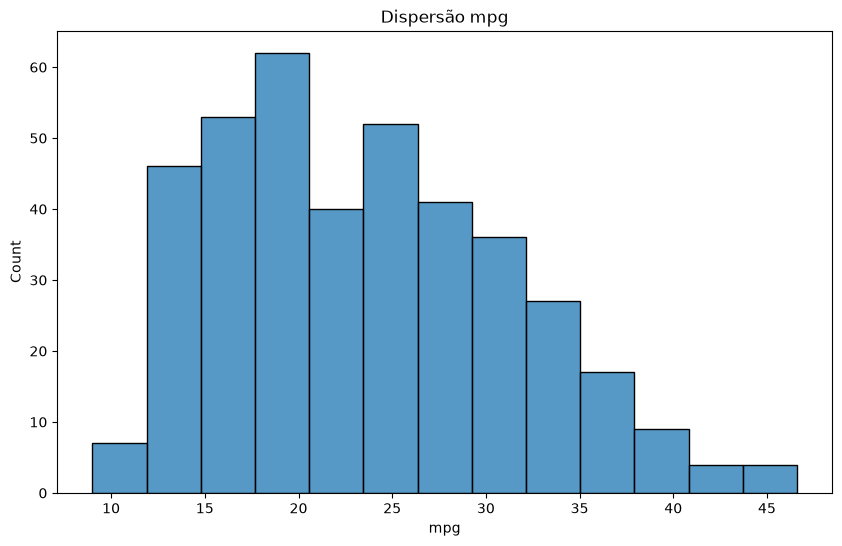

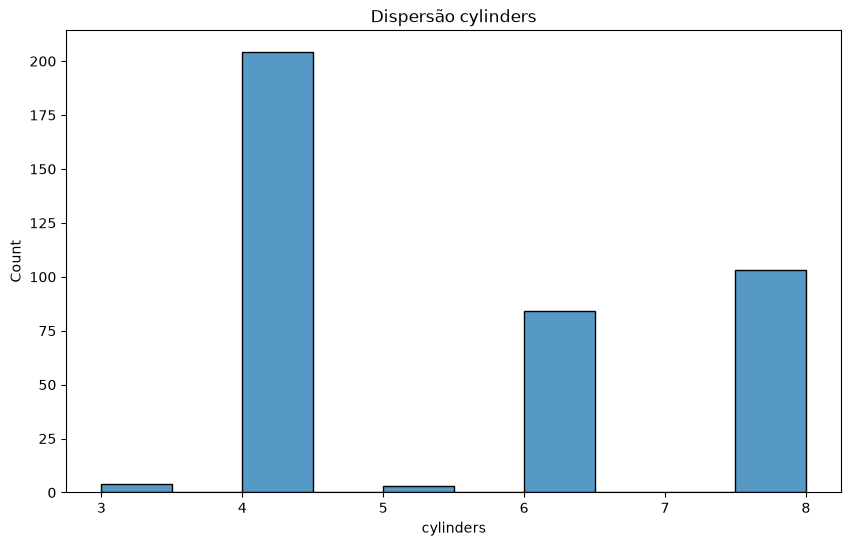

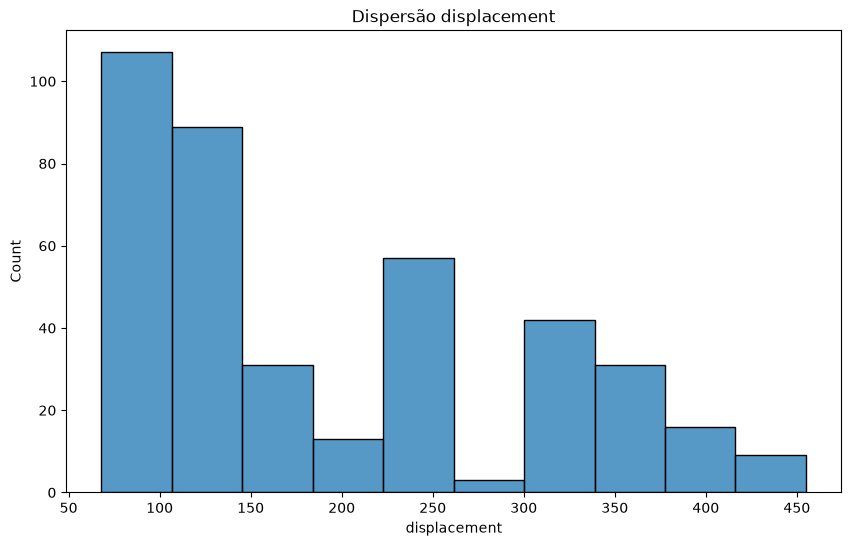

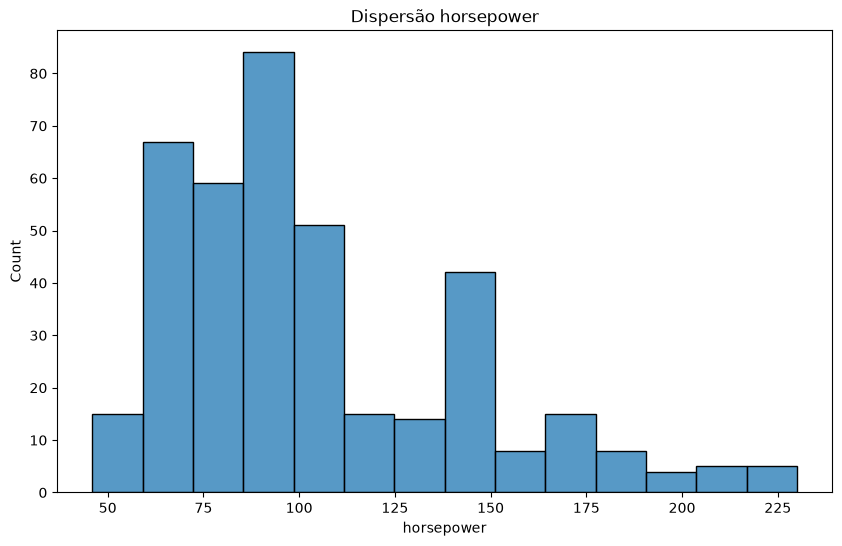

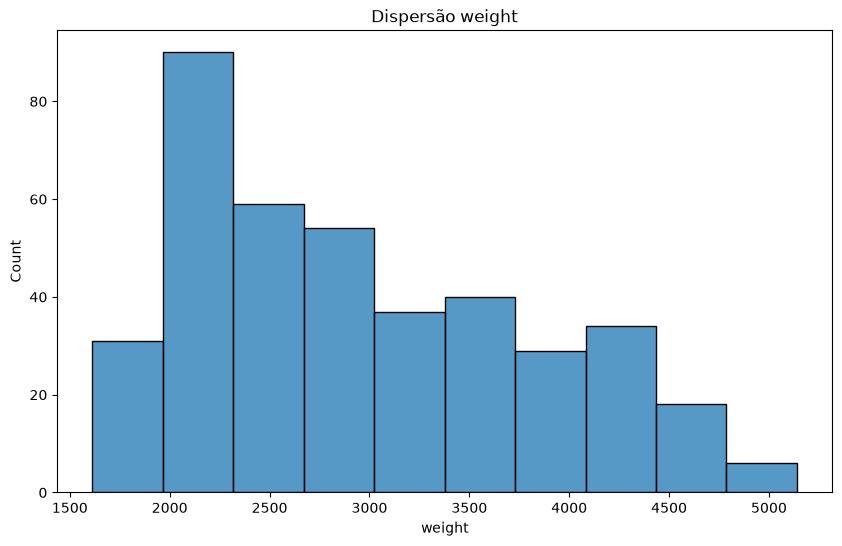

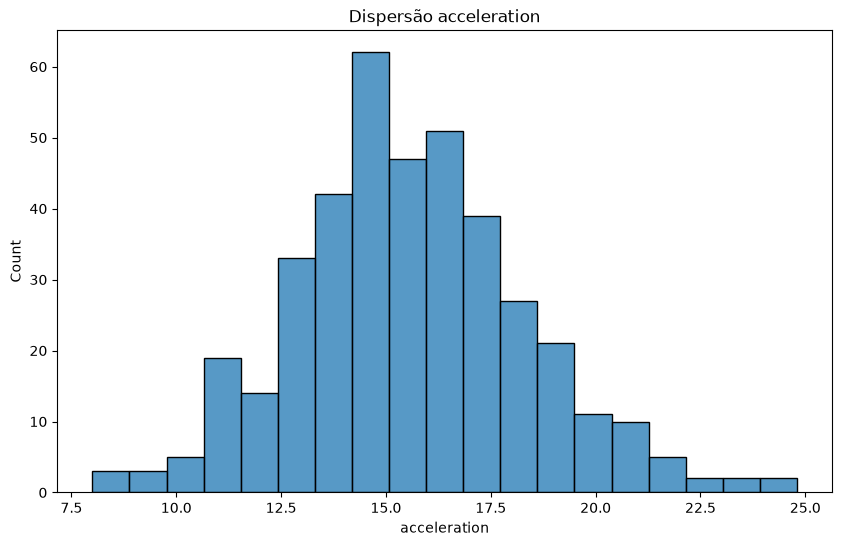

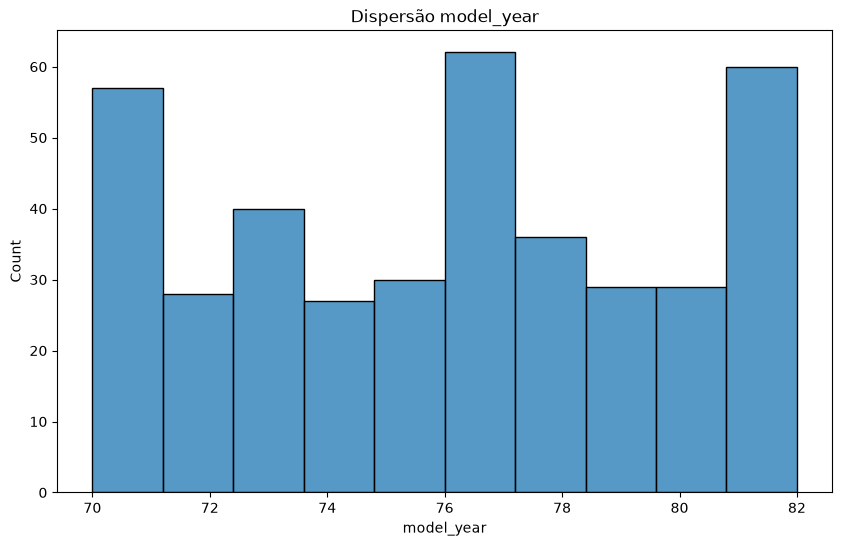

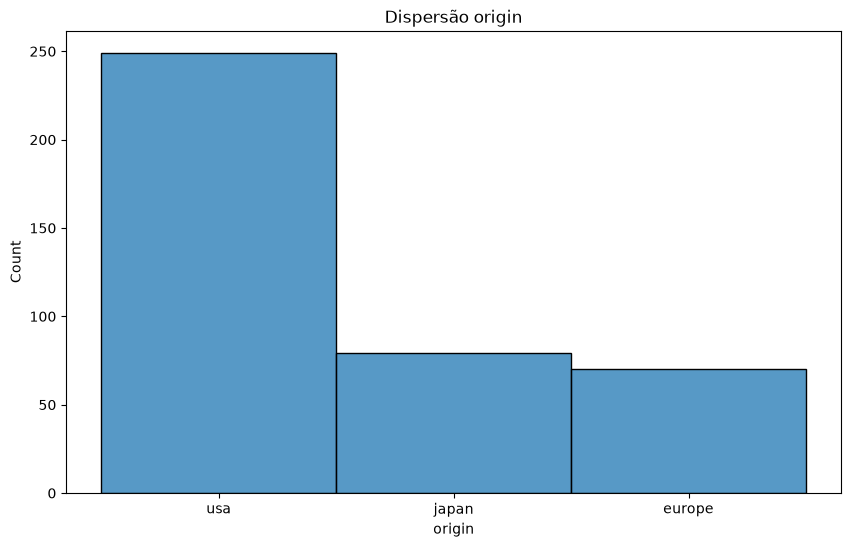

In [15]:
# Visualização
# Distribuição

for var in dados.columns:
    if var == "name":
        continue
    fig, ax = plt.subplots(figsize = (10,6))
    sns.histplot(data=dados[var], ax = ax)
    ax.set_title(f"Dispersão {var}")
    plt.show()

In [16]:
# Temos 6 valores faltantes na coluna 'horsepower' vamos dropar esses registros para não ter que assumir valores.
model_data = dados.dropna(subset=['horsepower'])

In [17]:
# Modelo
model = smf.ols("mpg ~ horsepower + weight", data = model_data).fit()

In [18]:
# Análise do modelo

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     467.9
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          3.06e-104
Time:                        01:07:30   Log-Likelihood:                -1121.0
No. Observations:                 392   AIC:                             2248.
Df Residuals:                     389   BIC:                             2260.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     45.6402      0.793     57.540      0.000      44.081      47.200
horsepower    -0.0473      0.011     -4.267      0.000      -0.069      -0.026
weight        -0.0058      0.001    -11.535      0.000      -0.007      -0.005
==============================================================================
Omnibus:                       35.336   Durbin-Watson:                   0.858
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.973
Skew:                           0.683   Prob(JB):                     1.04e-10
Kurtosis:                       3.974   Cond. No.                     1.15e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.15e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

O modelo explica aproximadamente 70% da variabilidade dos nossos dados, vemos isso olhando o valor de R^2. O R^2 Ajustado penaliza o modelo de acordo com o número de preditores que adicionamos, por isso, ele penaliza preditores que não ajudam na avaliação de um modelo.

Olhando os coeficiêntes preditos, devemos nos atentar no intervalo de confiança (IC) do estimador. O padrão é assumir um erro do tipo 1 de 5% (alpha = 5%), isto é, que se repetíssemos o experimento 100x, esperamos que em 95 deles o intervalo contém de fato o valor real do parâmetro. Como é um teste de hipotese bilateral, temos que o IC(95%) não pode conter o valor 0, pois nesse caso, o efeito do parâmetro pode ser nulo na previsão da variável resposta (ausência de efeito). 

	        coef	std err	t	P>|t|	[0.025	0.975]
Intercept	45.6402	0.793	57.540	0.000	44.081	47.200
horsepower	-0.0473	0.011	-4.267	0.000	-0.069	-0.026
weight	-0.0058	0.001	-11.535	0.000	-0.007	-0.005


No nosso caso, vemos que os estimadores para "weight" e "horsepower" não contém o 0 no intervalo de confiança, então rejeitamos a hipótese nula de que os efeitos são nulos e usamos suas estimativas para a previsão de "mpg".

Uma etapa importante da análise de qualquer modelo é a análise dos resíduos. Em um modelo de regressão linear, assumimos que a parte aleatória (os erros) são normalmente distribuídos com média 0 (o modelo erra igualmente para mais e para menos e sua distribuição tem formato de sino), além de assumir que a variância é constante (homocedasticidade) e podemos avaliar isso nos gráficos "Q-Q plot" e de resíduos ordenados por exemplo.

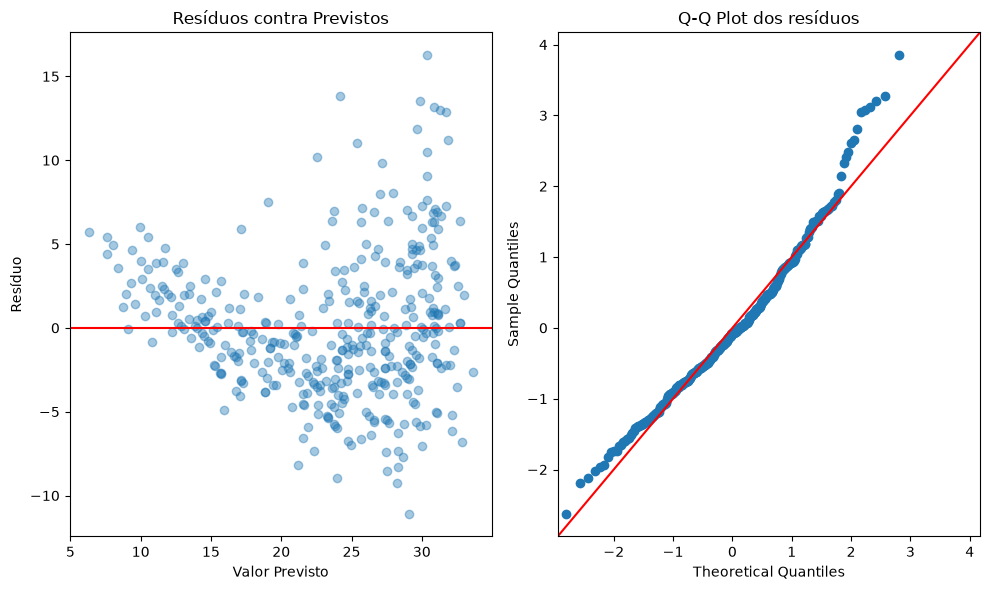

In [19]:
# Análise de resíduos

residuos = model.resid
valores_ajustados = model.fittedvalues

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10,6))

# residuos contra previstos
ax[0].scatter(valores_ajustados, residuos, alpha=0.4) # scatter plot de ajustados vs preditos
ax[0].axhline(0, color = 'red') # adiciona linha horizontal no valor 0 na cor 'red'
ax[0].set_xlabel("Valor Previsto")
ax[0].set_ylabel("Resíduo")
ax[0].set_title("Resíduos contra Previstos")

sm.qqplot(residuos, line = '45', fit = True, ax = ax[1]) # quantil quantil dos residuos,  no grafico da coluna 2 (ax[1])
ax[1].set_title("Q-Q Plot dos resíduos")

fig.tight_layout()





Observe que o gráfico "Resíduos contra Previstos" deveria apresentar uma nuvem de pontos sem forma e aparenta ter um formato de "U", indicando que deve haver uma relação não linear nos dados que o modelo não está capturando. Note que esse mesmo gráfico apresenta um funil crescente, vemos a heterocedasticidade dos resíduos(outro problema de modelagem).

Já no gráfico "Q-Q Plot dos resíduos" vemos caudas pesadas, o que indica que os resíduos não apresentam uma forma de sino.

In [21]:
# Modelo 2
model_data['log_mpg'] = np.log(model_data['mpg'])

model_2 = smf.ols("log_mpg ~ horsepower + weight", data = model_data).fit()

# Modelo 3
model_3 = smf.ols("mpg ~ horsepower + I(weight**2)", data = model_data).fit()

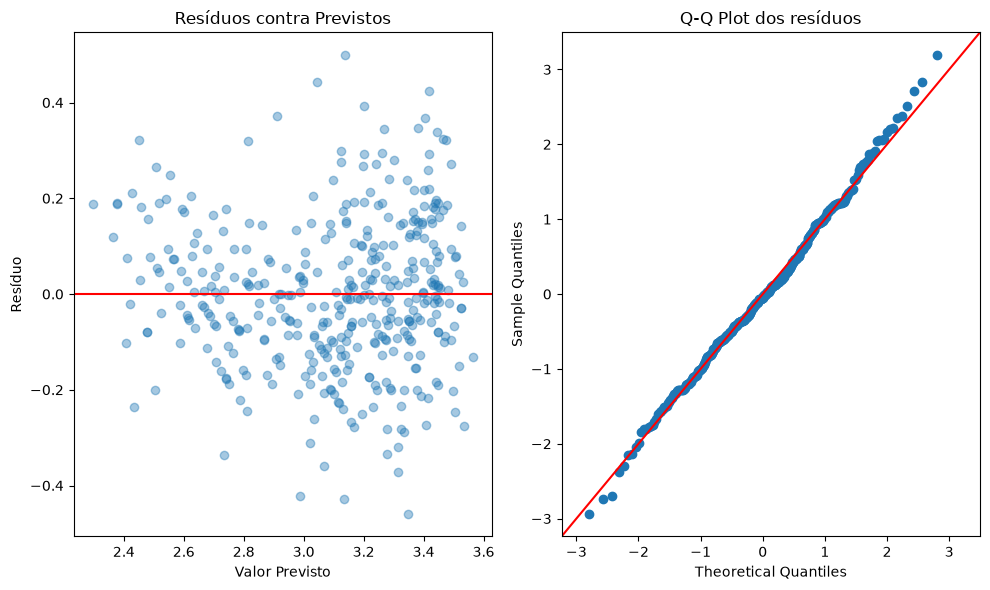

In [22]:
# Análise de resíduos

residuos = model_2.resid
valores_ajustados = model_2.fittedvalues

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10,6))

# residuos contra previstos
ax[0].scatter(valores_ajustados, residuos, alpha=0.4) # scatter plot de ajustados vs preditos
ax[0].axhline(0, color = 'red') # adiciona linha horizontal no valor 0 na cor 'red'
ax[0].set_xlabel("Valor Previsto")
ax[0].set_ylabel("Resíduo")
ax[0].set_title("Resíduos contra Previstos")

sm.qqplot(residuos, line = '45', fit = True, ax = ax[1]) # quantil quantil dos residuos,  no grafico da coluna 2 (ax[1])
ax[1].set_title("Q-Q Plot dos resíduos")

fig.tight_layout()





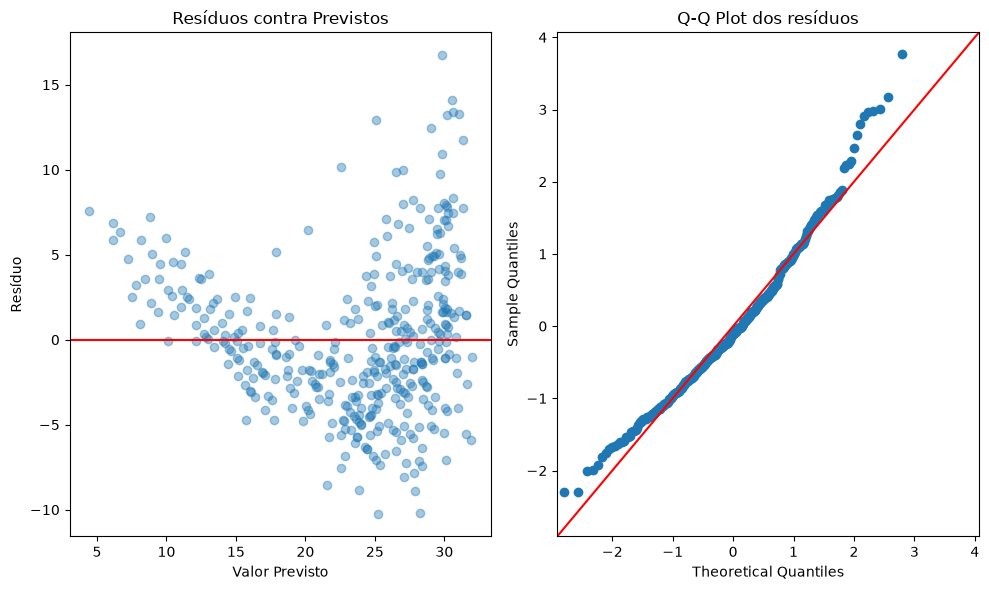

In [23]:
# Análise de resíduos

residuos = model_3.resid
valores_ajustados = model_3.fittedvalues

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10,6))

# residuos contra previstos
ax[0].scatter(valores_ajustados, residuos, alpha=0.4) # scatter plot de ajustados vs preditos
ax[0].axhline(0, color = 'red') # adiciona linha horizontal no valor 0 na cor 'red'
ax[0].set_xlabel("Valor Previsto")
ax[0].set_ylabel("Resíduo")
ax[0].set_title("Resíduos contra Previstos")

sm.qqplot(residuos, line = '45', fit = True, ax = ax[1]) # quantil quantil dos residuos,  no grafico da coluna 2 (ax[1])
ax[1].set_title("Q-Q Plot dos resíduos")

fig.tight_layout()





Veja que o modelo que considera o peso ao quadrado (modelo 3), ainda apresenta heterocedasticidade e assimetria à direita (pontos acima da reta de 45° no Q-Q plot).

Já o modelo que faz uma transformação logaritmica na variavel resposta apresenta homocedasticidade e resíduos menos assimétricos.